In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("Fraud Detection Dataset.csv")
print(df.shape)
df.head()

(51000, 12)


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0


In [3]:
df.columns.tolist()
list(df)

['Transaction_ID',
 'User_ID',
 'Transaction_Amount',
 'Transaction_Type',
 'Time_of_Transaction',
 'Device_Used',
 'Location',
 'Previous_Fraudulent_Transactions',
 'Account_Age',
 'Number_of_Transactions_Last_24H',
 'Payment_Method',
 'Fraudulent']

In [4]:
df=df.dropna()

In [5]:
missing_percent = df.isnull().mean()*100

print(missing_percent)

Transaction_ID                      0.0
User_ID                             0.0
Transaction_Amount                  0.0
Transaction_Type                    0.0
Time_of_Transaction                 0.0
Device_Used                         0.0
Location                            0.0
Previous_Fraudulent_Transactions    0.0
Account_Age                         0.0
Number_of_Transactions_Last_24H     0.0
Payment_Method                      0.0
Fraudulent                          0.0
dtype: float64


In [6]:
duplicates = df.duplicated().sum()

print("Duplicate Records:", duplicates)

Duplicate Records: 688


In [7]:
dup_table = pd.DataFrame({
    "Duplicate_Count": [df[c].duplicated().sum() for c in df.columns],
    "Unique_Values": [df[c].nunique() for c in df.columns],
}, index=df.columns)
dup_table["Duplicate_%"] = (dup_table["Duplicate_Count"] / len(df) * 100).round(2)
dup_table

,Duplicate_Count,Unique_Values,Duplicate_%
Transaction_ID,787,38796,1.99
User_ID,35583,4000,89.89
Transaction_Amount,2667,36916,6.74
Transaction_Type,39578,5,99.99
Time_of_Transaction,39559,24,99.94
Device_Used,39579,4,99.99
Location,39575,8,99.98
Previous_Fraudulent_Transactions,39578,5,99.99
Account_Age,39464,119,99.70
Number_of_Transactions_Last_24H,39569,14,99.96


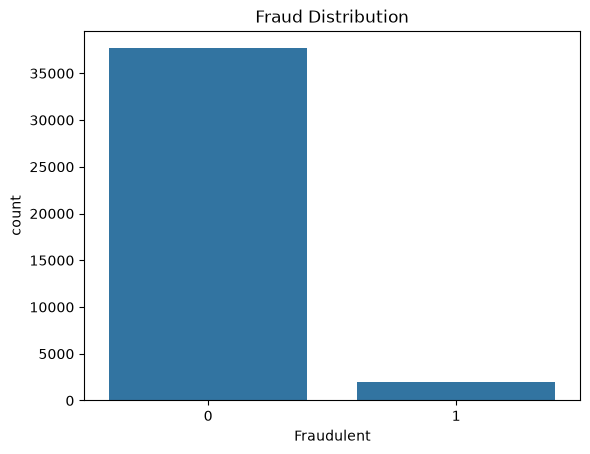

In [8]:
sns.countplot(x="Fraudulent", data=df)

plt.title("Fraud Distribution")

plt.show()

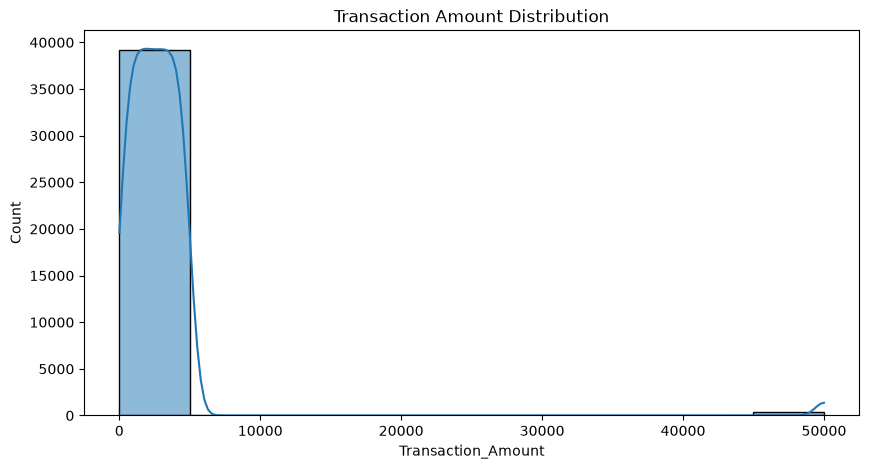

In [9]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["Transaction_Amount"],
    bins=10,
    kde=True
)

plt.title("Transaction Amount Distribution")

plt.show()

Fraudulent         0    1  Fraud_Rate_%
Payment_Method                         
Credit Card     9009  460          4.86
Debit Card      9167  456          4.74
Invalid Method  1174   56          4.55
Net Banking     9029  474          4.99
UPI             9272  486          4.98


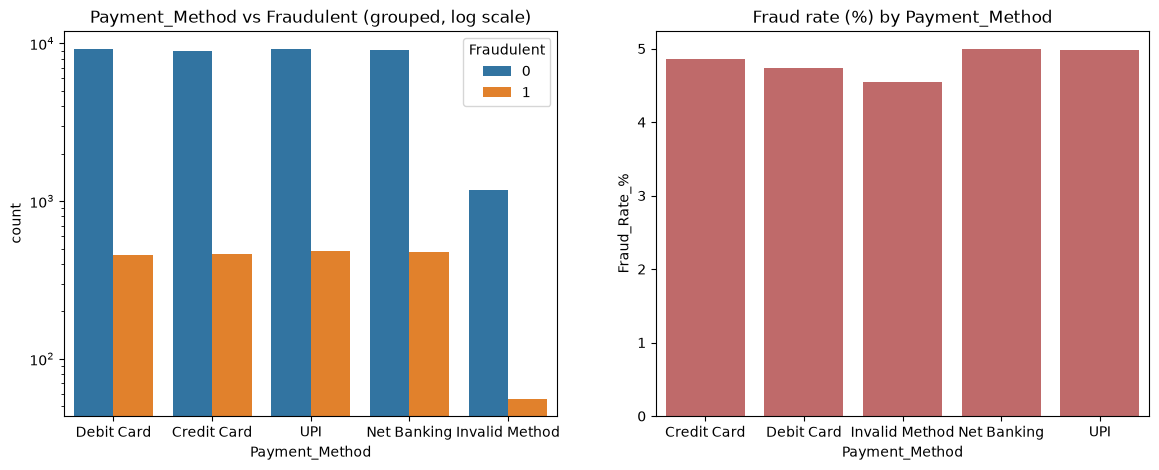

In [10]:
pay_fraud = pd.crosstab(df["Payment_Method"], df["Fraudulent"])
pay_fraud["Fraud_Rate_%"] = (pay_fraud[1] / pay_fraud.sum(axis=1) * 100).round(2)
print(pay_fraud)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x="Payment_Method", hue="Fraudulent", data=df, ax=ax[0])
ax[0].set_yscale("log")
ax[0].set_title("Payment_Method vs Fraudulent (grouped, log scale)")
sns.barplot(x=pay_fraud.index, y=pay_fraud["Fraud_Rate_%"], ax=ax[1], color="indianred")
ax[1].set_title("Fraud rate (%) by Payment_Method")
plt.show()

<Axes: >

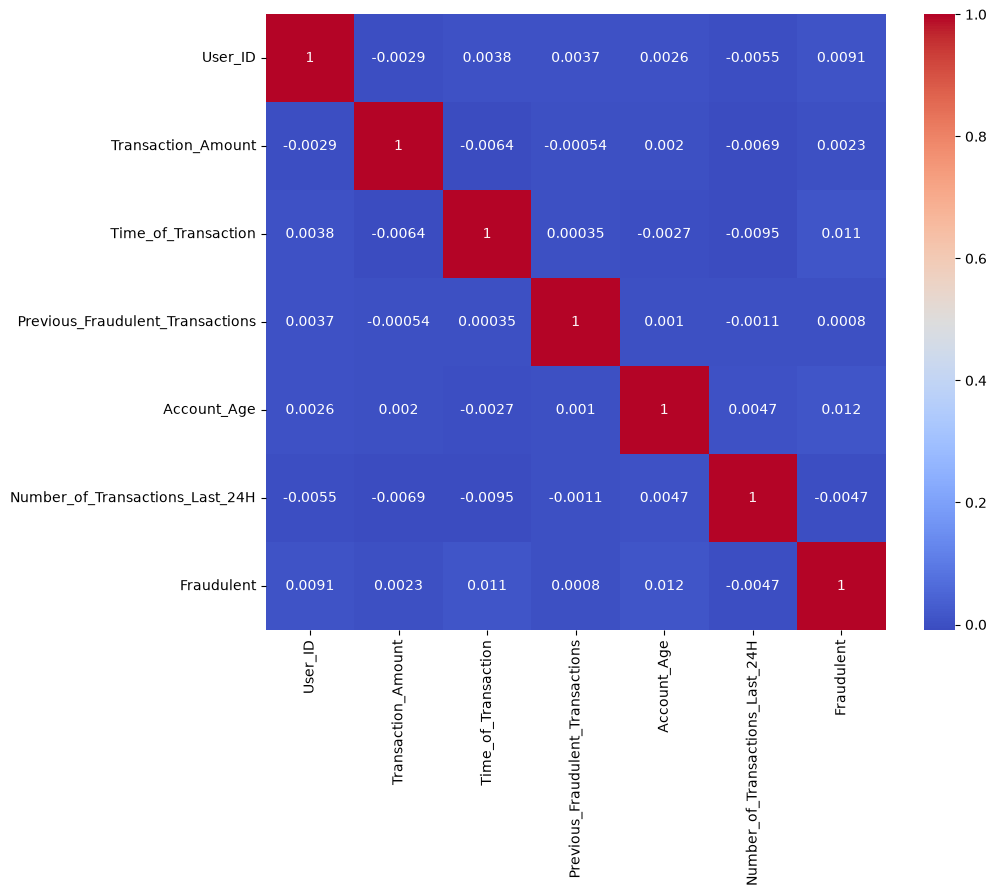

In [11]:
numeric = df.select_dtypes(include="number")

plt.figure(figsize=(10,8))

sns.heatmap(

numeric.corr(),

annot=True,

cmap="coolwarm"

)

# Outlier 

Text(0.5, 1.0, 'Transaction Amount Boxplot')

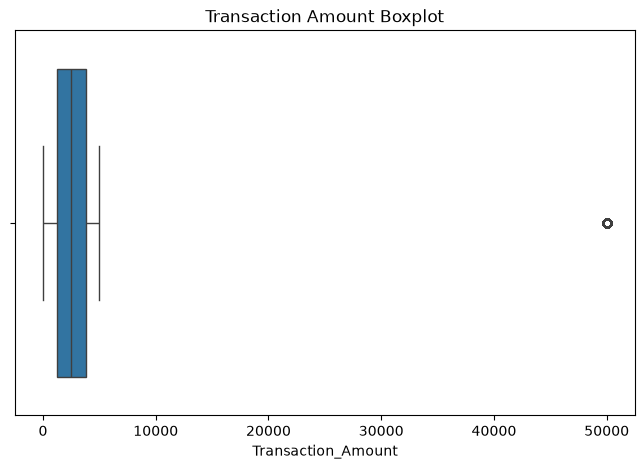

In [12]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=df["Transaction_Amount"]
)

plt.title("Transaction Amount Boxplot")

In [13]:
Q1 = df["Transaction_Amount"].quantile(0.25)

Q3 = df["Transaction_Amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5*IQR

upper = Q3 + 1.5*IQR


outliers = df[
    (df["Transaction_Amount"] < lower) |
    (df["Transaction_Amount"] > upper)
]

#Lower_outlier= df[df["Transaction_Amount"] < lower]

#Lower_outlier.head()

#upper_outlier= df[df["Transaction_Amount"] < upper]

#upper_outlier.head()
#upper_outlier.shape
#Lower_outlier.shape
print(outliers.shape)
#outliers.head()

(416, 12)


IQR bounds: [-13.0, 35.0]  ->  outliers found: 0


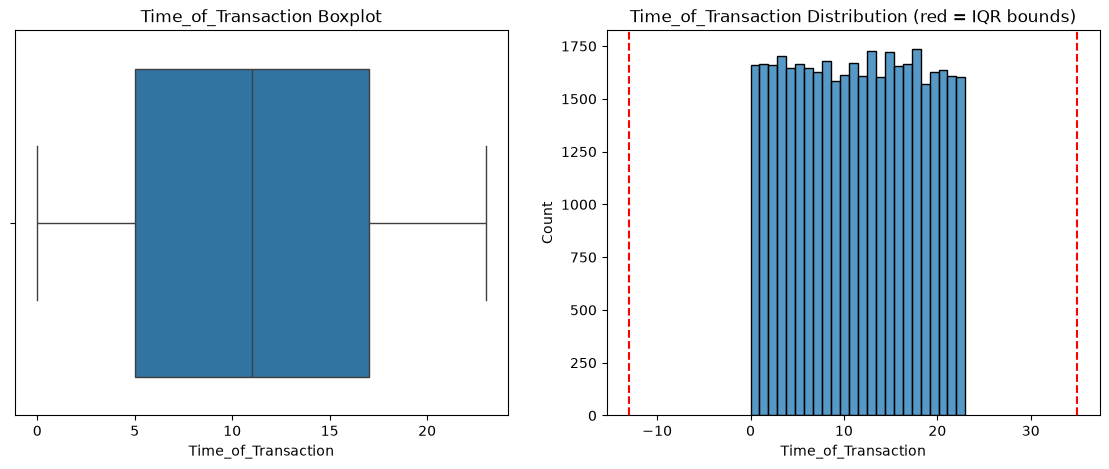

In [14]:
Q1_t = df["Time_of_Transaction"].quantile(0.25)
Q3_t = df["Time_of_Transaction"].quantile(0.75)
IQR_t = Q3_t - Q1_t
lower_t = Q1_t - 1.5 * IQR_t
upper_t = Q3_t + 1.5 * IQR_t

time_outliers = df[(df["Time_of_Transaction"] < lower_t) | (df["Time_of_Transaction"] > upper_t)]
print(f"IQR bounds: [{lower_t}, {upper_t}]  ->  outliers found: {len(time_outliers)}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=df["Time_of_Transaction"], ax=ax[0])
ax[0].set_title("Time_of_Transaction Boxplot")
sns.histplot(df["Time_of_Transaction"], bins=24, ax=ax[1])
ax[1].axvline(lower_t, color="red", ls="--"); ax[1].axvline(upper_t, color="red", ls="--")
ax[1].set_title("Time_of_Transaction Distribution (red = IQR bounds)")
plt.show()

Time_of_Transaction is an hour of day (0–23), so it is bounded and the IQR rule flags no outliers. Transactions are spread across all hours; no hour is statistically extreme.

**Common vs uncommon values.** A value is *common* if it makes up at least 10% of its column, and *uncommon* if it makes up less than 5%.

In [15]:
cat_cols = ["Transaction_Type", "Device_Used", "Location", "Payment_Method"]

rows = []
for col in cat_cols:
    share = df[col].value_counts(normalize=True) * 100
    print(f"--- {col} ---")
    print(share.round(2).to_string())
    for v, p in share.items():
        status = "Common" if p >= 10 else ("Uncommon" if p < 5 else "Moderate")
        rows.append((col, v, round(p, 2), status))

freq_table = pd.DataFrame(rows, columns=["Column", "Value", "Share_%", "Status"])
print("Uncommon values:")
freq_table[freq_table["Status"] == "Uncommon"]

--- Transaction_Type ---
Transaction_Type
Bank Transfer      20.24
Bill Payment       20.12
ATM Withdrawal     19.93
POS Payment        19.88
Online Purchase    19.82
--- Device_Used ---
Device_Used
Desktop           32.43
Tablet            32.28
Mobile            32.17
Unknown Device     3.13
--- Location ---
Location
Boston           12.75
Seattle          12.62
New York         12.54
Los Angeles      12.49
Chicago          12.46
San Francisco    12.45
Miami            12.37
Houston          12.32
--- Payment_Method ---
Payment_Method
UPI               24.65
Debit Card        24.31
Net Banking       24.01
Credit Card       23.92
Invalid Method     3.11
Uncommon values:


,Column,Value,Share_%,Status
8,Device_Used,Unknown Device,3.13,Uncommon
21,Payment_Method,Invalid Method,3.11,Uncommon


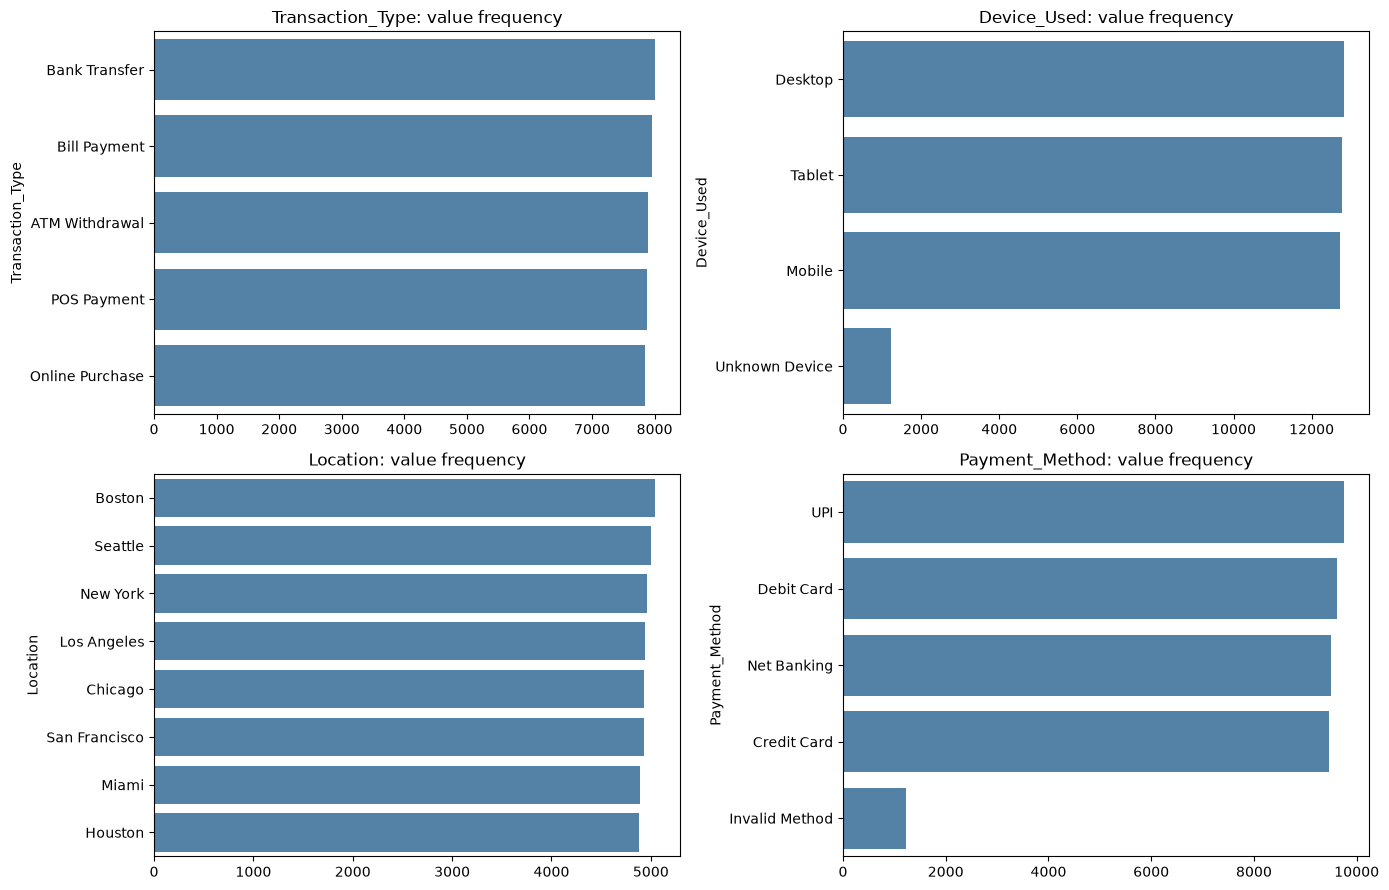

Previous_Fraudulent_Transactions | most common: 2 (8083) | least common: 3 (7798)
Number_of_Transactions_Last_24H | most common: 5 (2934) | least common: 9 (2693)


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    vc = df[col].value_counts()
    sns.barplot(x=vc.values, y=vc.index, ax=ax, color="steelblue")
    ax.set_title(f"{col}: value frequency")
plt.tight_layout(); plt.show()

# numeric columns: most and least frequent values
for col in ["Previous_Fraudulent_Transactions", "Number_of_Transactions_Last_24H"]:
    vc = df[col].value_counts()
    print(col, "| most common:", vc.index[0], f"({vc.iloc[0]})", "| least common:", vc.index[-1], f"({vc.iloc[-1]})")

In [17]:
features = [
    "Transaction_Amount",
    "Previous_Fraudulent_Transactions",
    "Account_Age",
    "Number_of_Transactions_Last_24H"
]


In [18]:
from sklearn.preprocessing import StandardScaler

X = df[features]
#X=X.dropna()
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


In [19]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.8,
    min_samples=15
)

labels = dbscan.fit_predict(X_scaled)

In [20]:
df["Cluster"] = labels
#df.head()
df["Cluster"].value_counts()

Cluster
 0    39167
 1      408
-1        8
Name: count, dtype: int64

Anomalies on a different feature set (Transaction_Amount, Time_of_Transaction, Account_Age, Number_of_Transactions_Last_24H) are computed in the **Task 5 (new feature set)** cells at the end of this notebook.

In [21]:
suspicious = df[df["Cluster"] == -1]

print(suspicious.head())

      Transaction_ID  User_ID  Transaction_Amount Transaction_Type  \
317             T318     4681             49997.8     Bill Payment   
8146           T8147     1640             49997.8     Bill Payment   
15441         T15442     4030             49997.8    Bank Transfer   
19824         T19825     2206             49997.8  Online Purchase   
22058         T22059     3612             49997.8    Bank Transfer   

       Time_of_Transaction Device_Used     Location  \
317                    0.0      Mobile      Houston   
8146                  17.0      Tablet  Los Angeles   
15441                 20.0     Desktop      Seattle   
19824                 14.0      Mobile        Miami   
22058                 20.0      Tablet     New York   

       Previous_Fraudulent_Transactions  Account_Age  \
317                                   4            4   
8146                                  4            7   
15441                                 0            5   
19824                   

### Task 5: Cluster Graph (any two attributes)

In [22]:
x_attr = "Transaction_Amount"   
y_attr = "Previous_Fraudulent_Transactions"          


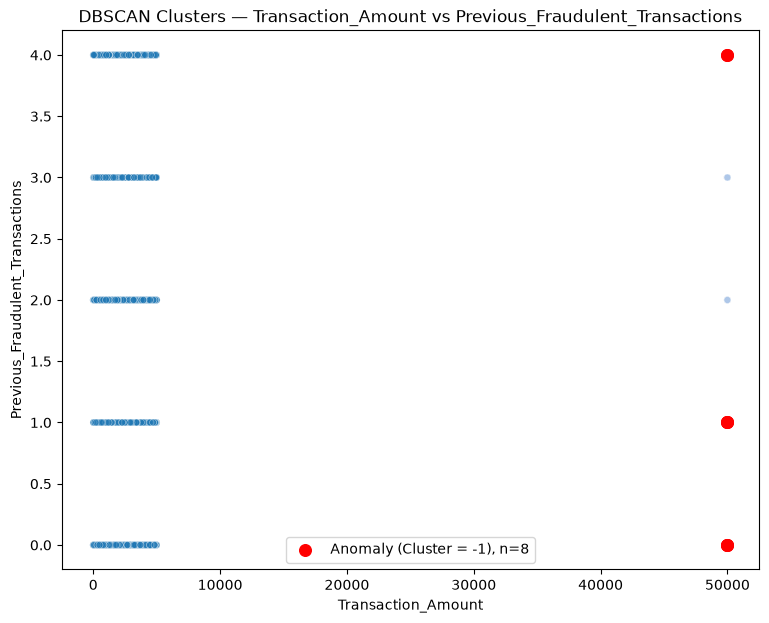

In [23]:
non_noise = df[df["Cluster"] != -1]
noise = df[df["Cluster"] == -1]

sample_size = min(3000, len(non_noise))
plot_sample = non_noise.sample(n=sample_size, random_state=42)

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=plot_sample,
    x=x_attr, y=y_attr,
    hue="Cluster",
    palette="tab20",
    alpha=0.6, s=25,
    legend=False
)

plt.scatter(
    noise[x_attr], noise[y_attr],
    c="red", marker="o", s=70,
    label=f"Anomaly (Cluster = -1), n={len(noise)}"
)

plt.xlabel(x_attr)
plt.ylabel(y_attr)
plt.title(f"DBSCAN Clusters — {x_attr} vs {y_attr}")
plt.legend()
plt.show()


### Task 5 (new feature set): Anomalies with Cluster = -1

In [24]:
features_v2 = ["Transaction_Amount", "Time_of_Transaction", "Account_Age", "Number_of_Transactions_Last_24H"]

X2 = df[features_v2]
X2_scaled = StandardScaler().fit_transform(X2)

dbscan2 = DBSCAN(eps=0.5, min_samples=10)
df["Cluster_v2"] = dbscan2.fit_predict(X2_scaled)

print(df["Cluster_v2"].value_counts())
anomalies_v2 = df[df["Cluster_v2"] == -1]
anomalies_v2.head()

Cluster_v2
 0    39167
-1      314
 4       22
 1       19
 3       17
 2       16
 5       11
 6       10
 7        7
Name: count, dtype: int64


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent,Cluster,Cluster_v2
245,T246,2306,49997.8,Bill Payment,1.0,Desktop,New York,3,78,9,UPI,0,1,-1
317,T318,4681,49997.8,Bill Payment,0.0,Mobile,Houston,4,4,14,Credit Card,0,-1,-1
504,T505,4863,49997.8,Online Purchase,6.0,Tablet,Boston,2,85,14,Net Banking,0,1,-1
551,T552,2982,49997.8,Bill Payment,17.0,Tablet,Chicago,3,37,7,Invalid Method,1,1,-1
561,T562,3617,49997.8,Bill Payment,14.0,Tablet,Chicago,3,10,3,Credit Card,0,1,-1


### Task 6: Graphs for Anomalies

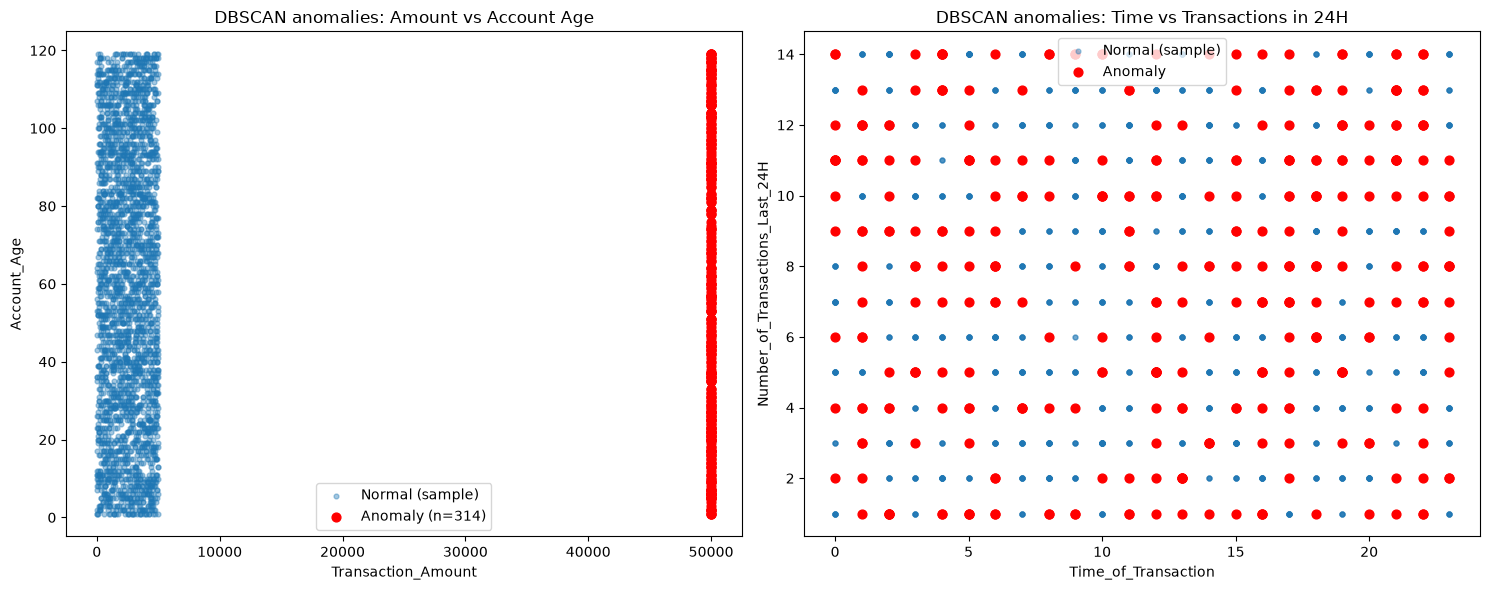

In [25]:
normal2 = df[df["Cluster_v2"] != -1].sample(n=min(3000, (df["Cluster_v2"] != -1).sum()), random_state=42)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))

ax[0].scatter(normal2["Transaction_Amount"], normal2["Account_Age"], s=12, alpha=0.4, label="Normal (sample)")
ax[0].scatter(anomalies_v2["Transaction_Amount"], anomalies_v2["Account_Age"], c="red", s=40, label=f"Anomaly (n={len(anomalies_v2)})")
ax[0].set_xlabel("Transaction_Amount"); ax[0].set_ylabel("Account_Age")
ax[0].set_title("DBSCAN anomalies: Amount vs Account Age"); ax[0].legend()

ax[1].scatter(normal2["Time_of_Transaction"], normal2["Number_of_Transactions_Last_24H"], s=12, alpha=0.4, label="Normal (sample)")
ax[1].scatter(anomalies_v2["Time_of_Transaction"], anomalies_v2["Number_of_Transactions_Last_24H"], c="red", s=40, label="Anomaly")
ax[1].set_xlabel("Time_of_Transaction"); ax[1].set_ylabel("Number_of_Transactions_Last_24H")
ax[1].set_title("DBSCAN anomalies: Time vs Transactions in 24H"); ax[1].legend()
plt.tight_layout(); plt.show()

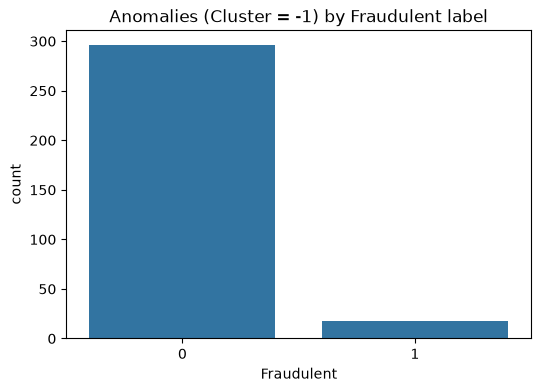

Fraud rate among anomalies: 5.73 %
Fraud rate overall: 4.88 %


In [26]:
plt.figure(figsize=(6, 4))
sns.countplot(x="Fraudulent", data=anomalies_v2)
plt.title("Anomalies (Cluster = -1) by Fraudulent label")
plt.show()

print("Fraud rate among anomalies:", round(anomalies_v2["Fraudulent"].mean() * 100, 2), "%")
print("Fraud rate overall:", round(df["Fraudulent"].mean() * 100, 2), "%")